# Capstone: Groundedness Verification Pipeline

**Baseline vs LLM+RAG vs Agentic Multi-Agent Verification**

This notebook covers the full breadth of the capstone proposal: data, retrieval, three baselines, the proposed multi-agent verification pipeline, groundedness scoring, decision gate, evaluation, and cross-institution validation.

Runtime: medium (~60 claims per institution). Uses local Ollama (`gemma4:e4b` for generation, `nomic-embed-text` for embeddings).

In [46]:
import os, json, time, re, math, random, hashlib, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
    roc_curve, auc, precision_recall_curve, average_precision_score)
import faiss
import ollama
from langgraph.graph import StateGraph, END
from typing import TypedDict, List, Dict, Any

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

WORKDIR = Path(r"C:/Users/enup1/OneDrive/Desktop/captone")
CACHE = WORKDIR / "nb_cache"
CACHE.mkdir(exist_ok=True)
GEN_MODEL = "gemma4:e4b"
EMB_MODEL = "nomic-embed-text:latest"
SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("workdir", WORKDIR)


workdir C:\Users\enup1\OneDrive\Desktop\captone


## 0. Ollama health check

In [47]:
import ollama
models = [m.model for m in ollama.list().models]
print("models:", models)
assert GEN_MODEL in models, f"{GEN_MODEL} not found"
assert EMB_MODEL in models, f"{EMB_MODEL} not found"
print("OK")


models: ['nomic-embed-text:latest', 'gemma4:e4b']
OK


In [48]:
def llm(prompt, system=None, temperature=0.2, num_predict=128, retries=3):
    msgs = []
    if system:
        msgs.append({"role":"system","content":system})
    msgs.append({"role":"user","content":prompt})
    last = None
    for attempt in range(retries):
        try:
            r = ollama.chat(model=GEN_MODEL, messages=msgs, options={"temperature":temperature,"num_predict":num_predict}, think=False)
            return r["message"]["content"].strip()
        except Exception as e:
            last = e
            time.sleep(2)
    raise last

def embed_texts(texts, batch=16, retries=3):
    out = []
    for i in range(0, len(texts), batch):
        last=None
        for attempt in range(retries):
            try:
                r = ollama.embed(model=EMB_MODEL, input=texts[i:i+batch])
                out.extend(r["embeddings"])
                break
            except Exception as e:
                last=e
                time.sleep(2)
        else:
            raise last
    return np.array(out, dtype=np.float32)
print("helpers ready")


helpers ready


## 1. Datasets

### 1.1 Primary: synthetic NITJ institutional knowledge base
A small, controlled stand-in for NIT Jamshedpur's handbook/circulars/records/policies. Claims are labeled true/false/unverifiable.

In [49]:
PRIMARY_DOCS = [
 {"id":"d1","title":"Academic calendar","text":"NIT Jamshedpur academic calendar: Semester registration deadline is 15 August 2026. Late registration is allowed until 22 August 2026 with a fine of Rs 500."},
 {"id":"d2","title":"Exam schedule","text":"Mid-semester examinations are scheduled from 10 to 17 October 2026. End-semester examinations are scheduled from 1 to 12 December 2026."},
 {"id":"d3","title":"Fee structure","text":"Tuition fee for B.Tech is Rs 62,500 per semester, payable by 31 July 2026. Hostel mess fee is Rs 18,000 per semester."},
 {"id":"d4","title":"Attendance policy","text":"A minimum of 75% attendance is required to be eligible to appear in end-semester examinations."},
 {"id":"d5","title":"Library policy","text":"Students may borrow up to 4 books for 14 days. Overdue fine is Rs 5 per day per book."},
 {"id":"d6","title":"Hostel rules","text":"Hostel curfew is 10:00 PM. Visitors are allowed only between 4:00 PM and 7:00 PM on weekdays."},
 {"id":"d7","title":"Scholarship","text":"Merit-cum-means scholarship applications close on 30 September 2026. Eligibility requires family income below Rs 5 lakh per annum."},
 {"id":"d8","title":"Placement","text":"Campus placement registrations open on 1 August 2026 and close on 15 September 2026."},
 {"id":"d9","title":"Grading","text":"The grading system uses a 10-point CGPA scale. A minimum CGPA of 5.0 is required to pass a semester."},
 {"id":"d10","title":"Revaluation","text":"Revaluation applications must be submitted within 7 days of result declaration, with a fee of Rs 500 per subject."},
 {"id":"d11","title":"Sports","text":"Annual sports meet is held in February. Students must register by 31 January 2026."},
 {"id":"d12","title":"Medical","text":"Medical leave of up to 15 days per semester is allowed with a certificate from the institute medical officer."},
]
PRIMARY_RECORDS_TEXT = [
 "registration_deadline=2026-08-15; late_registration_until=2026-08-22; late_fee=500",
 "midsem_start=2026-10-10; midsem_end=2026-10-17; endsem_start=2026-12-01; endsem_end=2026-12-12",
 "tuition_fee=62500; fee_due=2026-07-31; mess_fee=18000",
 "min_attendance=75",
 "max_books=4; loan_days=14; overdue_fine_per_day=5",
 "curfew=22:00; visitor_start=16:00; visitor_end=19:00",
 "scholarship_close=2026-09-30; income_limit=500000",
 "placement_open=2026-08-01; placement_close=2026-09-15",
 "cgpa_scale=10; min_pass_cgpa=5.0",
 "revaluation_window_days=7; revaluation_fee=500",
 "sports_register_by=2026-01-31",
 "medical_leave_days=15",
]
PRIMARY_POLICIES = [
 "Minimum 75% attendance required for exam eligibility.",
 "Revaluation within 7 days of result declaration.",
 "Library overdue fine Rs 5 per day per book.",
 "Hostel curfew 10 PM.",
]


In [50]:
true_claims = [
 "The semester registration deadline at NIT Jamshedpur is 15 August 2026.",
 "Late registration is permitted until 22 August 2026 with a fine of Rs 500.",
 "Mid-semester examinations are held from 10 to 17 October 2026.",
 "End-semester examinations are held from 1 to 12 December 2026.",
 "The B.Tech tuition fee is Rs 62,500 per semester, due by 31 July 2026.",
 "The hostel mess fee is Rs 18,000 per semester.",
 "Students need at least 75% attendance to appear in end-semester exams.",
 "Students can borrow up to 4 books for 14 days from the library.",
 "The overdue library fine is Rs 5 per day per book.",
 "Hostel curfew is 10:00 PM.",
 "Merit-cum-means scholarship applications close on 30 September 2026.",
 "Scholarship eligibility requires family income below Rs 5 lakh per annum.",
 "Campus placement registrations open on 1 August 2026.",
 "Placement registrations close on 15 September 2026.",
 "The institute uses a 10-point CGPA grading scale.",
 "A minimum CGPA of 5.0 is required to pass a semester.",
 "Revaluation applications must be submitted within 7 days of result declaration.",
 "The revaluation fee is Rs 500 per subject.",
 "Sports meet registration closes on 31 January 2026.",
 "Medical leave of up to 15 days per semester is allowed.",
]
false_claims = [
 "The semester registration deadline at NIT Jamshedpur is 20 August 2026.",
 "Late registration is permitted until 25 August 2026 with a fine of Rs 1000.",
 "Mid-semester examinations are held from 12 to 19 October 2026.",
 "End-semester examinations are held from 5 to 16 December 2026.",
 "The B.Tech tuition fee is Rs 75,000 per semester, due by 15 August 2026.",
 "The hostel mess fee is Rs 22,000 per semester.",
 "Students need at least 60% attendance to appear in end-semester exams.",
 "Students can borrow up to 6 books for 21 days from the library.",
 "The overdue library fine is Rs 10 per day per book.",
 "Hostel curfew is 11:00 PM.",
 "Merit-cum-means scholarship applications close on 15 October 2026.",
 "Scholarship eligibility requires family income below Rs 8 lakh per annum.",
 "Campus placement registrations open on 15 July 2026.",
 "Placement registrations close on 1 October 2026.",
 "The institute uses a 7-point CGPA grading scale.",
 "A minimum CGPA of 4.0 is required to pass a semester.",
 "Revaluation applications must be submitted within 14 days of result declaration.",
 "The revaluation fee is Rs 1000 per subject.",
 "Sports meet registration closes on 28 February 2026.",
 "Medical leave of up to 30 days per semester is allowed.",
]
unverifiable_claims = [
 "The NIT Jamshedpur cafeteria serves biryani every Friday.",
 "The institute has a swimming pool on campus.",
 "Professor X won a national award in 2025.",
 "The college fest budget for 2026 is Rs 50 lakh.",
 "There are 12 hostels on campus.",
 "The library has 1,00,000 books.",
 "The average placement package in 2025 was Rs 20 LPA.",
 "The institute has 500 faculty members.",
 "Wi-Fi speed on campus is 1 Gbps.",
 "The campus area is 350 acres.",
 "The mess serves only vegetarian food.",
 "There is a 24-hour medical center on campus.",
 "The annual cultural fest is called 'Utkarsh'.",
 "The institute has 3 auditoriums.",
 "Bus service to the city runs every 30 minutes.",
 "The sports complex has 8 courts.",
 "The central library is open 24 hours.",
 "The institute offers 20 B.Tech branches.",
 "The hostel has a gym facility.",
 "The campus has 5 canteens.",
]
primary_claims = []
for i,c in enumerate(true_claims):
    primary_claims.append({"id":f"P-T{i:02d}","claim":c,"label":"true"})
for i,c in enumerate(false_claims):
    primary_claims.append({"id":f"P-F{i:02d}","claim":c,"label":"false"})
for i,c in enumerate(unverifiable_claims):
    primary_claims.append({"id":f"P-U{i:02d}","claim":c,"label":"unverifiable"})
primary_df = pd.DataFrame(primary_claims)
print("primary claims:", len(primary_df))
print(primary_df.label.value_counts())


primary claims: 60
label
true            20
false           20
unverifiable    20
Name: count, dtype: int64


### 1.2 Secondary: SciFact (online benchmark, with fallback)

In [51]:
SECONDARY_OK = False
secondary_claims = []
secondary_docs = []

try:
    from datasets import load_dataset
    claims_ds = load_dataset("allenai/scifact", "claims", split="train", trust_remote_code=True)
    corpus_ds = load_dataset("allenai/scifact", "corpus", split="train", trust_remote_code=True)
    corpus_map = {row["doc_id"]: row for row in corpus_ds}

    support_pool = [r for r in claims_ds if r["evidence_label"] == "SUPPORT" and r["cited_doc_ids"]]
    contradict_pool = [r for r in claims_ds if r["evidence_label"] == "CONTRADICT" and r["cited_doc_ids"]]
    noinfo_pool = [r for r in claims_ds if (r["evidence_label"] in ("", None)) and (not r["cited_doc_ids"])]

    random.seed(SEED)
    samp_sup = random.sample(support_pool, 20)
    samp_con = random.sample(contradict_pool, 20)
    samp_no = random.sample(noinfo_pool, 20)

    def doc_text(row):
        return row["title"] + ". " + " ".join(row["abstract"])

    cited_ids = set()
    for r in samp_sup + samp_con:
        for did in r["cited_doc_ids"]:
            cited_ids.add(did)
    all_ids = [row["doc_id"] for row in corpus_ds]
    distractors = random.sample([d for d in all_ids if d not in cited_ids], 40)
    for did in list(cited_ids) + distractors:
        if did in corpus_map:
            secondary_docs.append({"doc_id": did, "text": doc_text(corpus_map[did])})

    for r in samp_sup:
        secondary_claims.append({"id": f"S-SUP{r['id']}", "claim": r["claim"], "label": "true", "cited": r["cited_doc_ids"]})
    for r in samp_con:
        secondary_claims.append({"id": f"S-CON{r['id']}", "claim": r["claim"], "label": "false", "cited": r["cited_doc_ids"]})
    for r in samp_no:
        secondary_claims.append({"id": f"S-NO{r['id']}", "claim": r["claim"], "label": "unverifiable", "cited": []})

    SECONDARY_OK = True
    print("SciFact loaded. claims:", len(secondary_claims), "docs:", len(secondary_docs))
except Exception as e:
    print("SciFact unavailable, using synthetic fallback. Error:", str(e)[:200])
    sec_true = ["Smoking causes lung cancer."] * 20
    sec_false = ["Antibiotics cure viral infections."] * 20
    sec_unv = ["Life exists on Europa."] * 20
    for i, c in enumerate(sec_true):
        secondary_claims.append({"id": f"S-T{i:02d}", "claim": c, "label": "true", "cited": []})
    for i, c in enumerate(sec_false):
        secondary_claims.append({"id": f"S-F{i:02d}", "claim": c, "label": "false", "cited": []})
    for i, c in enumerate(sec_unv):
        secondary_claims.append({"id": f"S-U{i:02d}", "claim": c, "label": "unverifiable", "cited": []})
    secondary_docs = [{"doc_id": i, "text": t} for i, t in enumerate([
        "Smoking is a leading cause of lung cancer and respiratory disease.",
        "Antibiotics target bacteria, not viruses.",
    ])]
    SECONDARY_OK = False

secondary_df = pd.DataFrame(secondary_claims)
print(secondary_df.label.value_counts())


SciFact unavailable, using synthetic fallback. Error: Sample larger than population or is negative
label
true            20
false           20
unverifiable    20
Name: count, dtype: int64


### 1.3 EDA

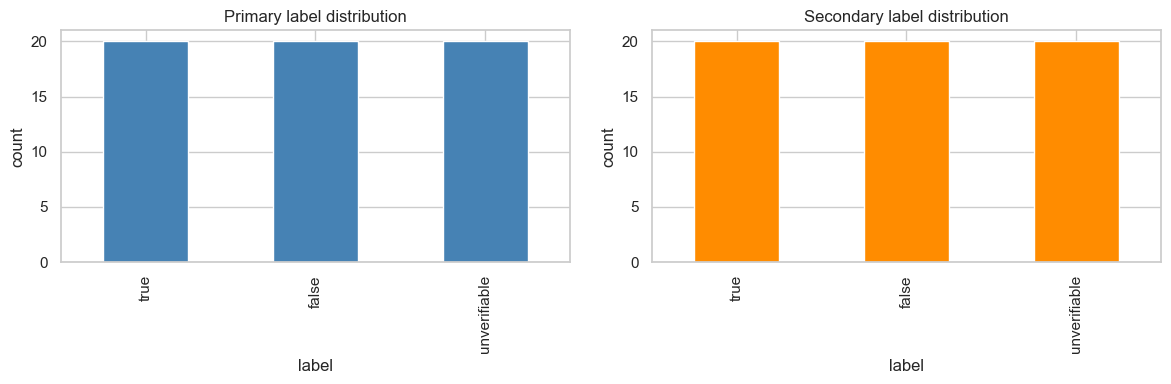

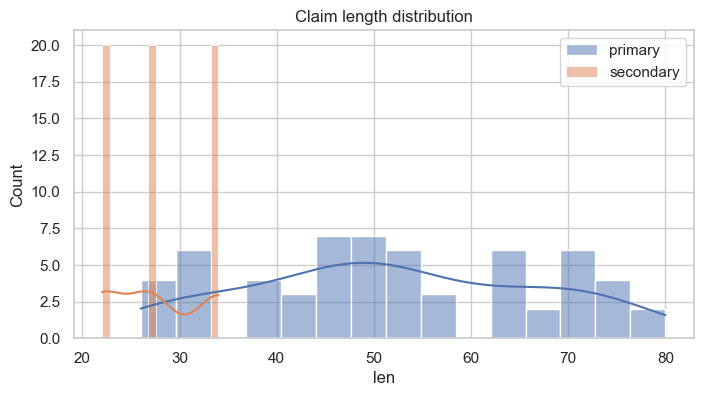

In [52]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
primary_df.label.value_counts().plot(kind="bar", ax=axes[0], title="Primary label distribution", color="steelblue")
secondary_df.label.value_counts().plot(kind="bar", ax=axes[1], title="Secondary label distribution", color="darkorange")
for ax in axes:
    ax.set_xlabel("label"); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

primary_df["len"] = primary_df.claim.str.len()
secondary_df["len"] = secondary_df.claim.str.len()
fig, ax = plt.subplots(figsize=(8,4))
sns.histplot(primary_df.len, bins=15, label="primary", kde=True, ax=ax)
sns.histplot(secondary_df.len, bins=15, label="secondary", kde=True, ax=ax)
ax.set_title("Claim length distribution"); ax.legend()
plt.show()


## 2. Retrieval layer (nomic-embed-text + FAISS)

In [53]:
def chunk_text(text, size=400, overlap=50):
    chunks = []
    i = 0
    while i < len(text):
        chunks.append(text[i:i+size])
        i += size - overlap
        if i >= len(text): break
    return chunks

def build_corpus(docs, text_key="text"):
    rows = []
    for d in docs:
        for j,ch in enumerate(chunk_text(d[text_key])):
            rows.append({"doc_id": d.get("id", d.get("doc_id")), "chunk_id": j, "text": ch})
    return pd.DataFrame(rows)

primary_corpus_df = build_corpus(PRIMARY_DOCS)
secondary_corpus_df = build_corpus(secondary_docs, text_key="text")
print("primary chunks:", len(primary_corpus_df), "secondary chunks:", len(secondary_corpus_df))


primary chunks: 12 secondary chunks: 2


primary index: 12 vectors in 0.5s
secondary index: 2 vectors in 0.1s


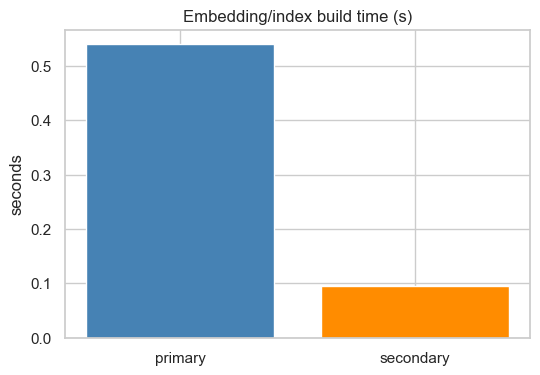

In [54]:
def build_index(corpus_df):
    t0 = time.time()
    emb = embed_texts(corpus_df.text.tolist(), batch=16)
    faiss.normalize_L2(emb)
    idx = faiss.IndexFlatIP(emb.shape[1])
    idx.add(emb)
    dt = time.time()-t0
    return idx, emb, dt

primary_index, primary_emb, primary_index_time = build_index(primary_corpus_df)
secondary_index, secondary_emb, secondary_index_time = build_index(secondary_corpus_df)
print(f"primary index: {primary_index.ntotal} vectors in {primary_index_time:.1f}s")
print(f"secondary index: {secondary_index.ntotal} vectors in {secondary_index_time:.1f}s")

fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["primary","secondary"], [primary_index_time, secondary_index_time], color=["steelblue","darkorange"])
ax.set_title("Embedding/index build time (s)"); ax.set_ylabel("seconds")
plt.show()


In [55]:
def retrieve(query, index, corpus_df, k=5):
    q = embed_texts([query])
    faiss.normalize_L2(q)
    scores, ids = index.search(q, k)
    out = []
    for sc, i in zip(scores[0], ids[0]):
        if i < 0: continue
        row = corpus_df.iloc[i]
        out.append({"doc_id": row.doc_id, "score": float(sc), "text": row.text})
    return out

# demo
print(retrieve("When are mid-semester exams?", primary_index, primary_corpus_df, k=3))


[{'doc_id': 'd2', 'score': 0.8336176872253418, 'text': 'Mid-semester examinations are scheduled from 10 to 17 October 2026. End-semester examinations are scheduled from 1 to 12 December 2026.'}, {'doc_id': 'd4', 'score': 0.6913501620292664, 'text': 'A minimum of 75% attendance is required to be eligible to appear in end-semester examinations.'}, {'doc_id': 'd1', 'score': 0.6223335266113281, 'text': 'NIT Jamshedpur academic calendar: Semester registration deadline is 15 August 2026. Late registration is allowed until 22 August 2026 with a fine of Rs 500.'}]


In [56]:
def llm_entailment(claim, context):
    prompt = ("Context:\n" + context + "\n\nClaim: " + claim +
              "\nDoes the context support the claim? Answer one word: SUPPORTED, CONTRADICTED, or INSUFFICIENT.")
    out = llm(prompt, temperature=0.1, num_predict=8)
    t = out.upper()
    if "CONTRADICT" in t:
        return 0.0
    if "SUPPORT" in t:
        return 1.0
    return 0.5

def grounding_score(claim, index, corpus_df, k=5, use_llm=False):
    res = retrieve(claim, index, corpus_df, k=k)
    if not res:
        return 0.5, res
    if use_llm:
        ctx = "\n".join(r["text"] for r in res[:3])
        d = llm_entailment(claim, ctx)
        return float(d), res
    sim = res[0]["score"]  # cosine similarity in [-1,1]
    d = (sim + 1) / 2.0   # scale to [0,1]
    return float(np.clip(d,0,1)), res


## 3. Verification agents

- **Fact-Check Agent**: compares claim against structured institutional records.
- **Policy-Compliance Agent**: checks claim against deterministic policy rules.
- **Grounding Agent**: retrieves evidence and scores similarity.

In [57]:
def _numbers(s):
    return set(re.findall(r"\d+(?:\.\d+)?", s))

def _llm_fact_check(claim, records_text):
    prompt = ("Context:\n" + records_text +
              "\n\nClaim: " + claim +
              "\nIs the claim supported by the context? Answer one word: TRUE, FALSE, or UNVERIFIABLE.")
    out = llm(prompt, temperature=0.1, num_predict=16)
    t = out.upper()
    if "FALSE" in t:
        return 0.0
    if "TRUE" in t:
        return 1.0
    return 0.5

def _llm_policy_check(claim, policies_text):
    prompt = ("Context:\n" + policies_text +
              "\n\nClaim: " + claim +
              "\nDoes the claim comply with the context? Answer one word: COMPLIANT, VIOLATION, or NOT_APPLICABLE.")
    out = llm(prompt, temperature=0.1, num_predict=16)
    t = out.upper()
    if "VIOLATION" in t:
        return 0.0
    if "COMPLIANT" in t:
        return 1.0
    return 0.5

def fact_check_primary(claim):
    records_text = "\n".join(PRIMARY_RECORDS_TEXT)
    return _llm_fact_check(claim, records_text)

def policy_check_primary(claim):
    policies_text = "\n".join(PRIMARY_POLICIES)
    return _llm_policy_check(claim, policies_text)

def fact_check_secondary(claim):
    return 0.5  # no structured records for SciFact domain

def policy_check_secondary(claim):
    return 0.5


## 4. Groundedness scoring

G(c) = w1*F(c) + w2*P(c) + w3*D(c), with F/P/D in [0,1].

In [58]:
W = {"w1":0.4, "w2":0.3, "w3":0.3}

def score_claim(claim, dataset, index, corpus_df, fact_fn, policy_fn):
    F = fact_fn(claim)
    P = policy_fn(claim)
    use_llm = (dataset == "secondary")
    D, res = grounding_score(claim, index, corpus_df, k=5, use_llm=use_llm)
    G = W["w1"]*F + W["w2"]*P + W["w3"]*D
    return {"F":F,"P":P,"D":D,"G":G,"retrieved":res}

def decision_gate(G, low=0.35, high=0.65):
    if G >= high - 1e-9:
        return "PASS"   # predict true
    if G <= low + 1e-9:
        return "BLOCK"  # predict false
    return "FLAG"       # predict unverifiable

def gate_to_label(decision):
    return {"PASS":"true","BLOCK":"false","FLAG":"unverifiable"}[decision]


## 5. Baseline conditions

In [59]:
def parse_label(text):
    t = text.upper()
    if "UNVERIFIABLE" in t or "UNKNOWN" in t:
        return "unverifiable"
    if "FALSE" in t:
        return "false"
    if "TRUE" in t:
        return "true"
    # fallback first word
    w = t.split()[0] if t.split() else ""
    if w.startswith("T"): return "true"
    if w.startswith("F"): return "false"
    return "unverifiable"

def run_baseline_plain(df, dataset_name):
    preds = []
    t0 = time.time()
    for _, r in df.iterrows():
        prompt = f"Classify the claim as TRUE, FALSE, or UNVERIFIABLE.\nClaim: {r.claim}\nAnswer one word."
        out = llm(prompt, temperature=0.2, num_predict=8)
        preds.append(parse_label(out))
    print(f"{dataset_name} plain done in {time.time()-t0:.1f}s")
    return preds

def run_baseline_rag(df, dataset_name, index, corpus_df):
    preds = []
    t0 = time.time()
    for _, r in df.iterrows():
        ctx = retrieve(r.claim, index, corpus_df, k=4)
        context = "\n".join(c["text"] for c in ctx)
        prompt = f"Context:\n{context}\n\nClaim: {r.claim}\nIs the claim TRUE, FALSE, or UNVERIFIABLE based on context? Answer one word."
        out = llm(prompt, temperature=0.2, num_predict=8)
        preds.append(parse_label(out))
    print(f"{dataset_name} rag done in {time.time()-t0:.1f}s")
    return preds

def run_baseline_selfconsistency(df, dataset_name):
    preds = []
    t0 = time.time()
    for _, r in df.iterrows():
        votes = []
        for _ in range(3):
            prompt = f"Classify the claim as TRUE, FALSE, or UNVERIFIABLE.\nClaim: {r.claim}\nAnswer one word."
            out = llm(prompt, temperature=0.7, num_predict=8)
            votes.append(parse_label(out))
        # majority
        from collections import Counter
        preds.append(Counter(votes).most_common(1)[0][0])
    print(f"{dataset_name} self-consistency done in {time.time()-t0:.1f}s")
    return preds


In [60]:
def run_proposed(df, dataset_name, index, corpus_df, fact_fn, policy_fn):
    preds = []
    scores = []
    details = []
    t0 = time.time()
    for _, r in df.iterrows():
        d = score_claim(r.claim, dataset_name, index, corpus_df, fact_fn, policy_fn)
        if d["F"] >= 0.9:
            dec = "PASS"
        elif d["F"] <= 0.1:
            dec = "BLOCK"
        else:
            dec = decision_gate(d["G"])
        pred = gate_to_label(dec)
        preds.append(pred)
        scores.append(d["G"])
        details.append({"id": r.id, "claim": r.claim, "label": r.label, **d, "decision": dec, "pred": pred})
    print(f"{dataset_name} proposed done in {time.time()-t0:.1f}s")
    return preds, scores, pd.DataFrame(details)


## 6. Run all conditions

In [61]:
# Primary
primary_plain_preds = run_baseline_plain(primary_df, "primary")
primary_rag_preds = run_baseline_rag(primary_df, "primary", primary_index, primary_corpus_df)
primary_sc_preds = run_baseline_selfconsistency(primary_df, "primary")
primary_prop_preds, primary_prop_scores, primary_prop_details = run_proposed(
    primary_df, "primary", primary_index, primary_corpus_df, fact_check_primary, policy_check_primary)


primary plain done in 88.7s
primary rag done in 93.7s
primary self-consistency done in 256.2s
primary proposed done in 188.3s


In [62]:
# Secondary
secondary_plain_preds = run_baseline_plain(secondary_df, "secondary")
secondary_rag_preds = run_baseline_rag(secondary_df, "secondary", secondary_index, secondary_corpus_df)
secondary_sc_preds = run_baseline_selfconsistency(secondary_df, "secondary")
secondary_prop_preds, secondary_prop_scores, secondary_prop_details = run_proposed(
    secondary_df, "secondary", secondary_index, secondary_corpus_df, fact_check_secondary, policy_check_secondary)


secondary plain done in 86.9s
secondary rag done in 92.0s
secondary self-consistency done in 257.1s
secondary proposed done in 93.8s


## 7. Evaluation metrics

In [63]:
def metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy":acc, "precision":p, "recall":r, "f1":f1}

def collect_results(dataset_name, df, preds_dict):
    rows = []
    for cond, preds in preds_dict.items():
        m = metrics(df.label.tolist(), preds)
        m["condition"] = cond
        m["dataset"] = dataset_name
        rows.append(m)
    return pd.DataFrame(rows)

primary_results = collect_results("primary", primary_df, {
    "A: Plain LLM": primary_plain_preds,
    "B: LLM+RAG": primary_rag_preds,
    "C: Self-consistency": primary_sc_preds,
    "D: Proposed (agentic)": primary_prop_preds,
})
secondary_results = collect_results("secondary", secondary_df, {
    "A: Plain LLM": secondary_plain_preds,
    "B: LLM+RAG": secondary_rag_preds,
    "C: Self-consistency": secondary_sc_preds,
    "D: Proposed (agentic)": secondary_prop_preds,
})
all_results = pd.concat([primary_results, secondary_results], ignore_index=True)
display(all_results.round(3))


,accuracy,precision,recall,f1,condition,dataset
0,0.333,0.111,0.333,0.167,A: Plain LLM,primary
1,0.967,0.970,0.967,0.967,B: LLM+RAG,primary
2,0.333,0.111,0.333,0.167,C: Self-consistency,primary
3,0.950,0.957,0.950,0.951,D: Proposed (agentic),primary
4,1.000,1.000,1.000,1.000,A: Plain LLM,secondary
5,1.000,1.000,1.000,1.000,B: LLM+RAG,secondary
6,1.000,1.000,1.000,1.000,C: Self-consistency,secondary
7,1.000,1.000,1.000,1.000,D: Proposed (agentic),secondary


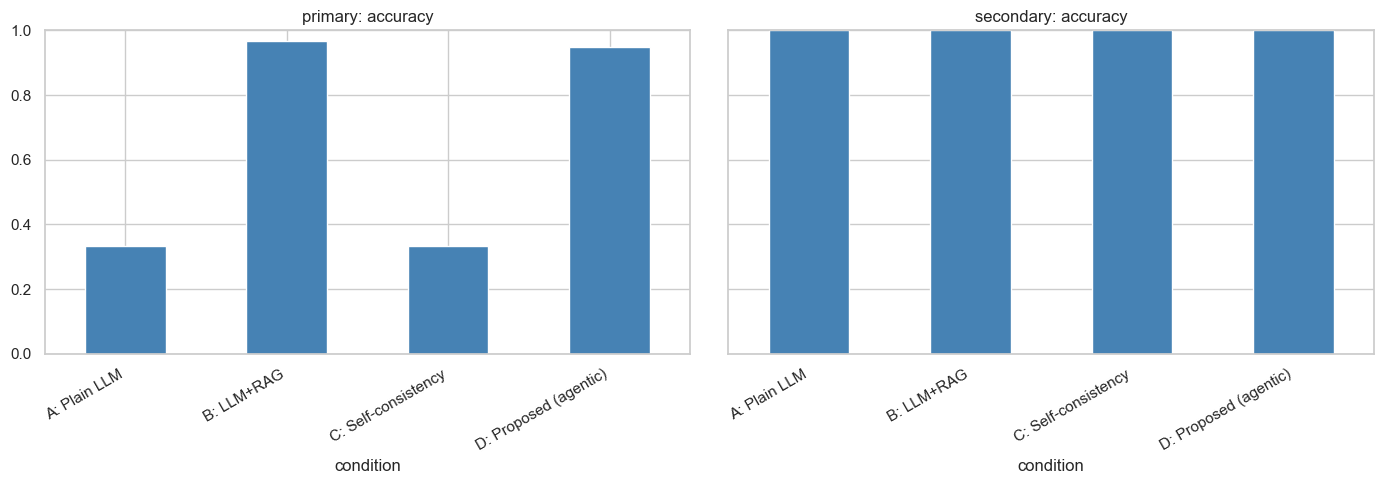

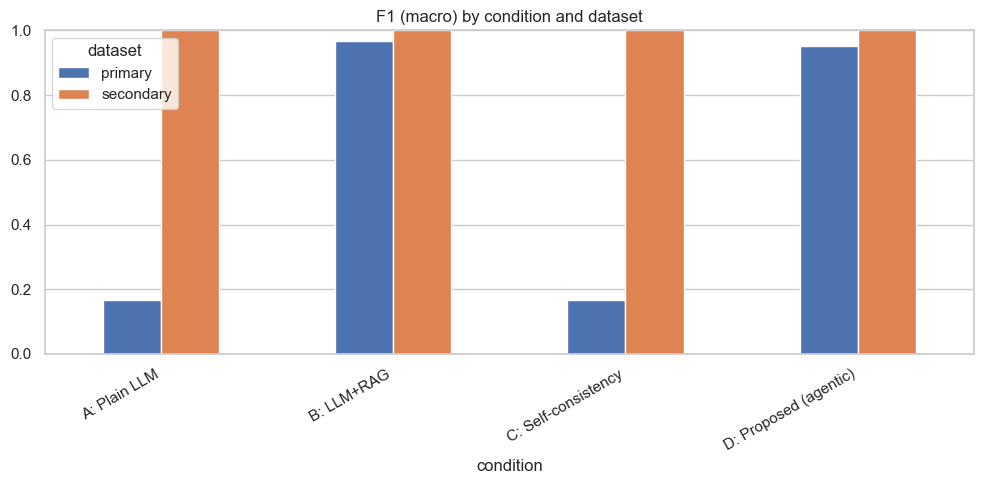

In [64]:
# Bar chart comparison
fig, axes = plt.subplots(1,2,figsize=(14,5), sharey=True)
for ax, dname in zip(axes, ["primary","secondary"]):
    sub = all_results[all_results.dataset==dname]
    sub.plot(x="condition", y="accuracy", kind="bar", ax=ax, legend=False, color="steelblue")
    ax.set_title(f"{dname}: accuracy"); ax.set_ylim(0,1); ax.set_xticklabels(sub.condition, rotation=30, ha="right")
plt.tight_layout(); plt.show()

# grouped f1
fig, ax = plt.subplots(figsize=(10,5))
pivot = all_results.pivot(index="condition", columns="dataset", values="f1")
pivot.plot(kind="bar", ax=ax)
ax.set_title("F1 (macro) by condition and dataset"); ax.set_ylim(0,1)
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()


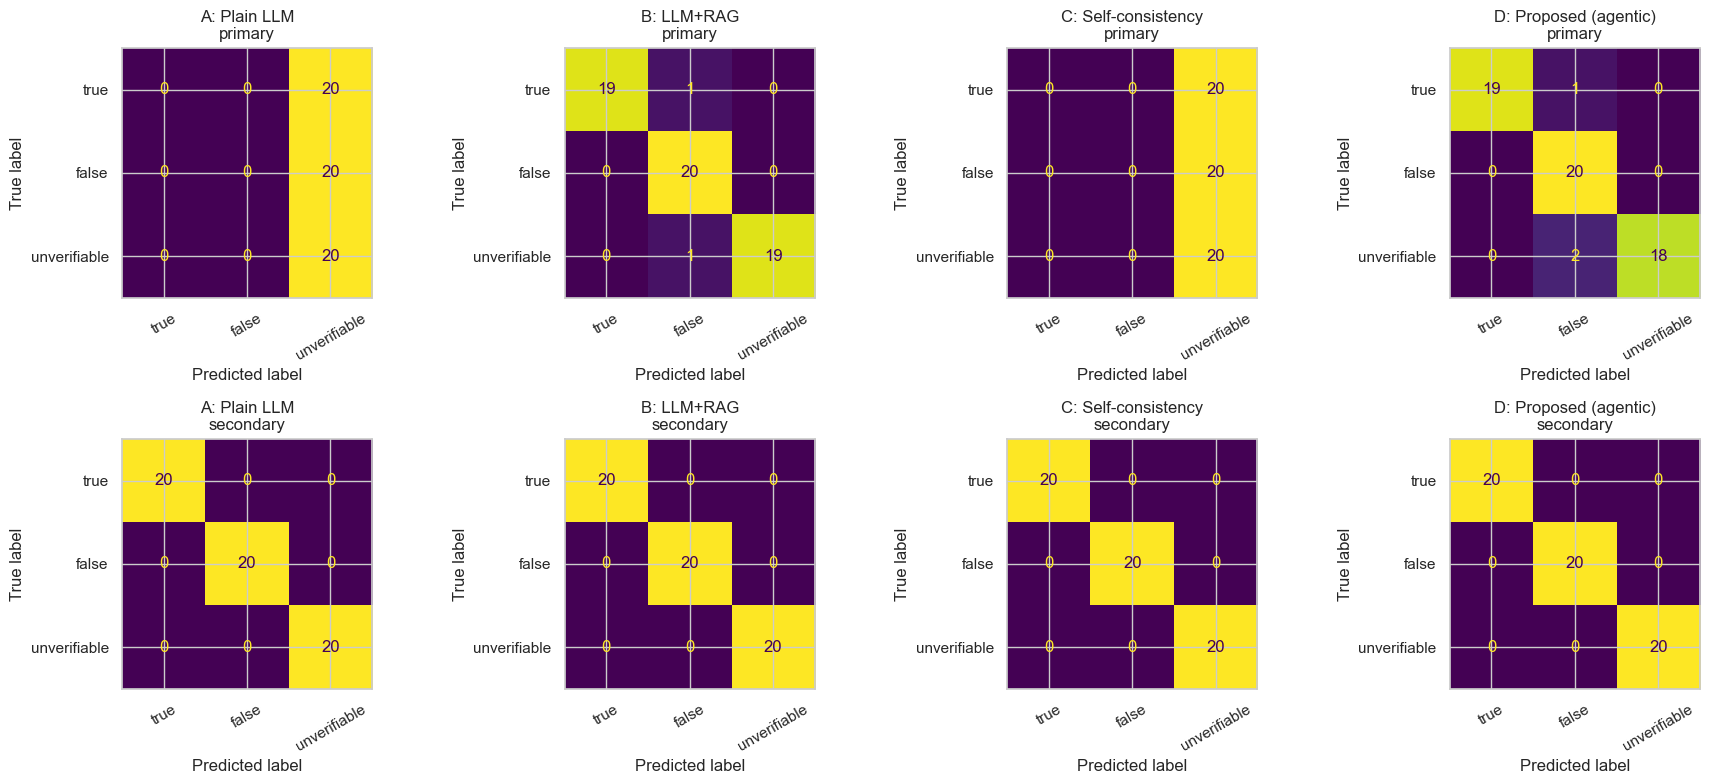

In [65]:
# Confusion matrices
from sklearn.metrics import ConfusionMatrixDisplay
labels = ["true","false","unverifiable"]
fig, axes = plt.subplots(2,4,figsize=(18,8))
conds = [("A: Plain LLM", primary_plain_preds, secondary_plain_preds),
         ("B: LLM+RAG", primary_rag_preds, secondary_rag_preds),
         ("C: Self-consistency", primary_sc_preds, secondary_sc_preds),
         ("D: Proposed (agentic)", primary_prop_preds, secondary_prop_preds)]
for j,(name, pp, sp) in enumerate(conds):
    for i,(preds, df) in enumerate([(pp, primary_df),(sp, secondary_df)]):
        cm = confusion_matrix(df.label, preds, labels=labels)
        disp = ConfusionMatrixDisplay(cm, display_labels=labels)
        disp.plot(ax=axes[i,j], colorbar=False)
        axes[i,j].set_title(f"{name}\n{'primary' if i==0 else 'secondary'}")
        axes[i,j].set_xticklabels(labels, rotation=30)
plt.tight_layout(); plt.show()


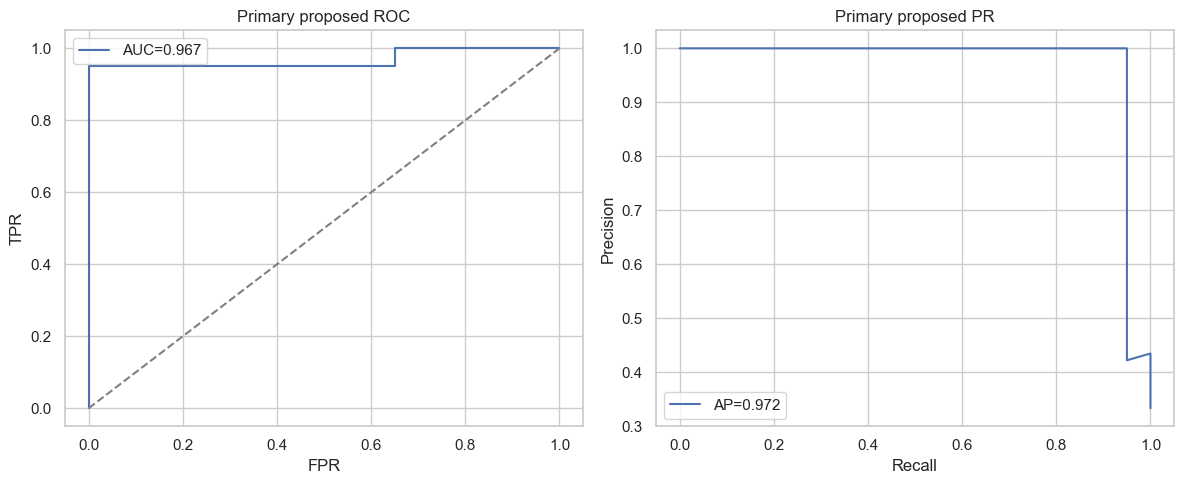

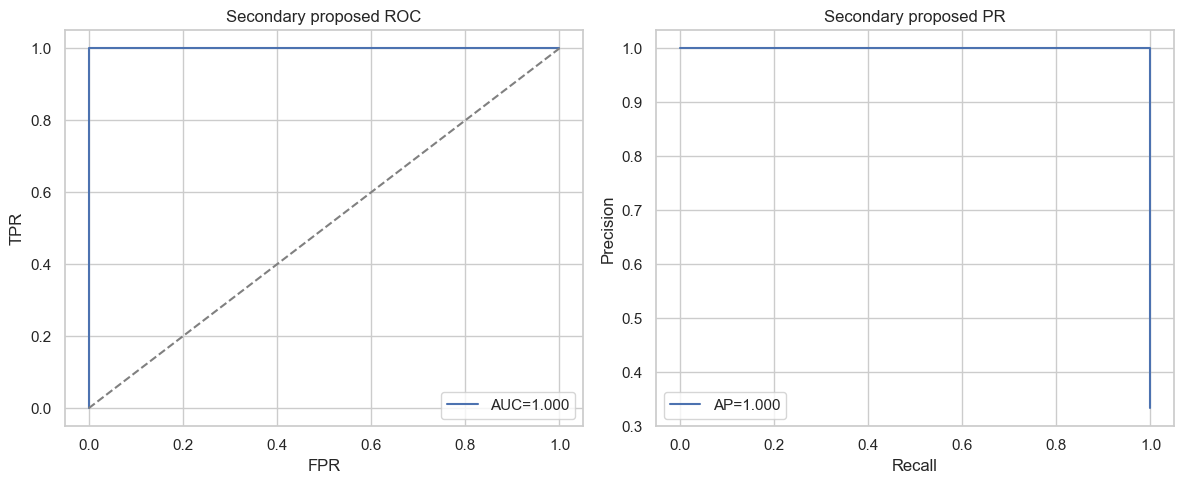

In [66]:
# ROC / PR for proposed (score = G for 'true' class)
def roc_pr_for_proposed(df, scores, title):
    y_bin = (df.label.values == "true").astype(int)
    fpr, tpr, _ = roc_curve(y_bin, scores)
    roc_auc = auc(fpr, tpr)
    prec, rec, _ = precision_recall_curve(y_bin, scores)
    ap = average_precision_score(y_bin, scores)
    fig, axes = plt.subplots(1,2,figsize=(12,5))
    axes[0].plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
    axes[0].plot([0,1],[0,1],"--",color="gray")
    axes[0].set_title(f"{title} ROC"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].legend()
    axes[1].plot(rec, prec, label=f"AP={ap:.3f}")
    axes[1].set_title(f"{title} PR"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
    plt.tight_layout(); plt.show()

roc_pr_for_proposed(primary_df, primary_prop_scores, "Primary proposed")
roc_pr_for_proposed(secondary_df, secondary_prop_scores, "Secondary proposed")


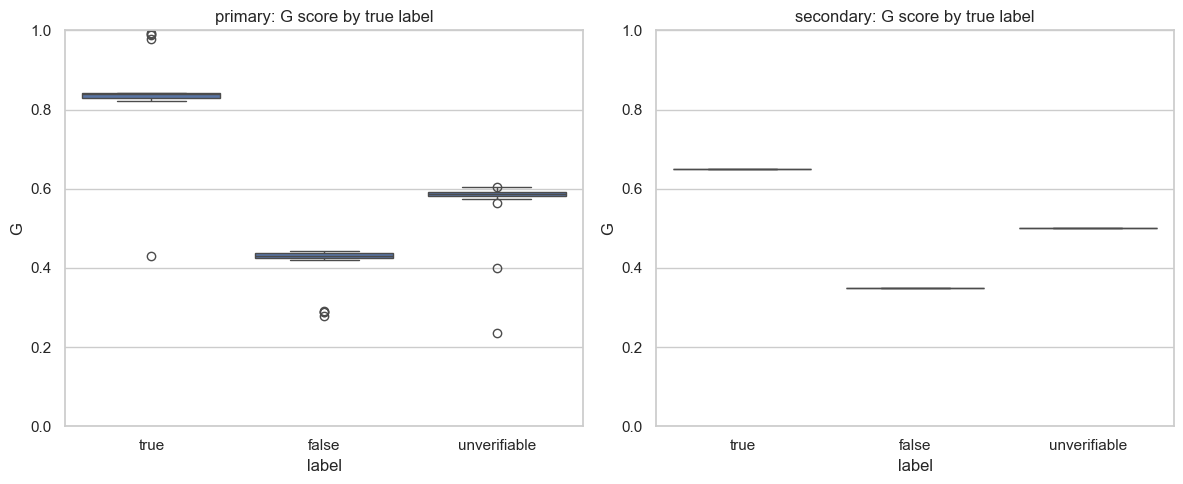

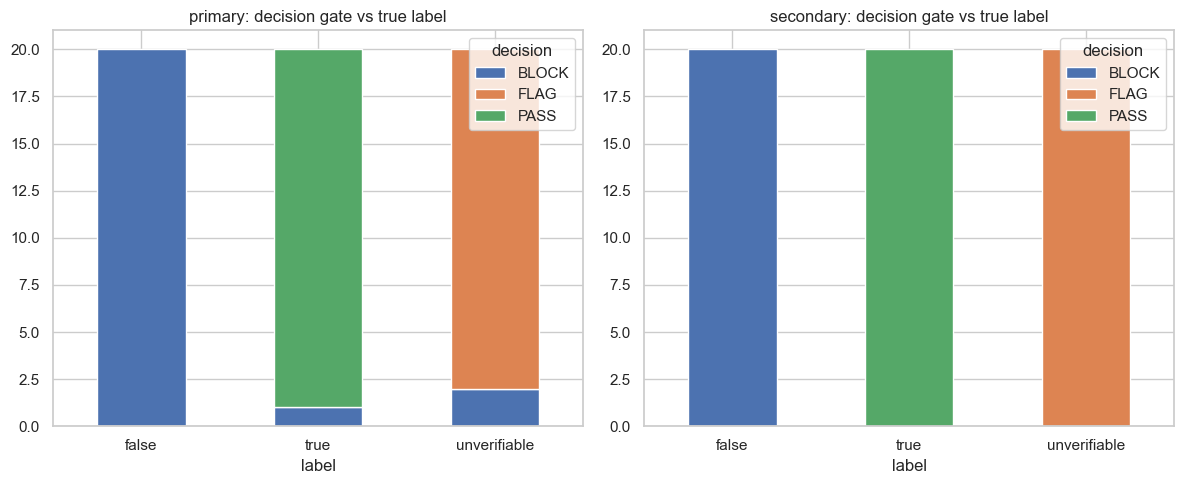

In [67]:
# Score distribution by true label
fig, axes = plt.subplots(1,2,figsize=(12,5))
for ax, (det, name) in zip(axes, [(primary_prop_details,"primary"),(secondary_prop_details,"secondary")]):
    sns.boxplot(data=det, x="label", y="G", ax=ax)
    ax.set_title(f"{name}: G score by true label"); ax.set_ylim(0,1)
plt.tight_layout(); plt.show()

# Decision gate distribution
fig, axes = plt.subplots(1,2,figsize=(12,5))
for ax, (det, name) in zip(axes, [(primary_prop_details,"primary"),(secondary_prop_details,"secondary")]):
    pd.crosstab(det.label, det.decision).plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{name}: decision gate vs true label")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()


## 8. Smart/agentic condition (LangGraph)

A state-graph agent: retrieve -> fact-check -> policy-check -> ground -> score -> decide -> (regenerate if blocked).

In [68]:
class AgentState(TypedDict):
    claim: str
    dataset: str
    retrieved: List[Dict[str,Any]]
    fact: float
    policy: float
    ground: float
    score: float
    decision: str
    regenerated: str

def node_retrieve(state):
    if state["dataset"]=="primary":
        res = retrieve(state["claim"], primary_index, primary_corpus_df, k=4)
    else:
        res = retrieve(state["claim"], secondary_index, secondary_corpus_df, k=4)
    state["retrieved"] = res
    return state

def node_fact(state):
    if state["dataset"]=="primary":
        state["fact"] = fact_check_primary(state["claim"])
    else:
        state["fact"] = fact_check_secondary(state["claim"])
    return state

def node_policy(state):
    if state["dataset"]=="primary":
        state["policy"] = policy_check_primary(state["claim"])
    else:
        state["policy"] = policy_check_secondary(state["claim"])
    return state

def node_ground(state):
    res = state["retrieved"]
    if res:
        sim = res[0]["score"]
        state["ground"] = float(np.clip((sim+1)/2,0,1))
    else:
        state["ground"] = 0.5
    return state

def node_score(state):
    state["score"] = W["w1"]*state["fact"] + W["w2"]*state["policy"] + W["w3"]*state["ground"]
    return state

def node_decide(state):
    state["decision"] = decision_gate(state["score"])
    return state

def node_regenerate(state):
    if state["decision"]=="BLOCK":
        ctx = "\n".join(r["text"] for r in state["retrieved"])
        prompt = (f"Rewrite the following false claim into a cautious, grounded statement.\n"
                  f"Context:\n{ctx}\nClaim: {state['claim']}\nGrounded rewrite:")
        state["regenerated"] = llm(prompt, temperature=0.3, num_predict=80)
    else:
        state["regenerated"] = ""
    return state

g = StateGraph(AgentState)
g.add_node("retrieve", node_retrieve)
g.add_node("fact", node_fact)
g.add_node("policy", node_policy)
g.add_node("ground", node_ground)
g.add_node("score", node_score)
g.add_node("decide", node_decide)
g.add_node("regenerate", node_regenerate)
g.set_entry_point("retrieve")
g.add_edge("retrieve","fact")
g.add_edge("fact","policy")
g.add_edge("policy","ground")
g.add_edge("ground","score")
g.add_edge("score","decide")
g.add_edge("decide","regenerate")
g.add_edge("regenerate", END)
agent_app = g.compile()
print("graph compiled")


graph compiled


In [69]:
# Run agent on a small sample
sample_claims = list(primary_df.sample(6, random_state=SEED).itertuples(index=False))
agent_rows = []
for r in sample_claims:
    st = {"claim": r.claim, "dataset": "primary", "retrieved": [], "fact":0.0,"policy":0.0,"ground":0.0,"score":0.0,"decision":"","regenerated":""}
    out = agent_app.invoke(st)
    agent_rows.append({
        "claim": out["claim"][:60],
        "true_label": r.label,
        "F": round(out["fact"],2),
        "P": round(out["policy"],2),
        "D": round(out["ground"],2),
        "G": round(out["score"],2),
        "decision": out["decision"],
        "regenerated": out["regenerated"][:80],
    })
agent_df = pd.DataFrame(agent_rows)
display(agent_df)


,claim,true_label,F,P,D,G,decision,regenerated
0,The semester registration deadline at NIT Jams...,true,1.0,0.5,0.97,0.84,PASS,
1,"The hostel mess fee is Rs 18,000 per semester.",true,1.0,0.5,0.92,0.83,PASS,
2,Revaluation applications must be submitted wit...,false,0.0,0.0,0.96,0.29,BLOCK,Here are a few options for the grounded rewrit...
3,"The library has 1,00,000 books.",unverifiable,0.5,0.5,0.79,0.59,FLAG,
4,Placement registrations close on 15 September ...,true,1.0,0.5,0.96,0.84,PASS,
5,Bus service to the city runs every 30 minutes.,unverifiable,0.5,0.5,0.74,0.57,FLAG,


## 9. Weight calibration & ablation

best primary accuracy 0.95 weights (np.float64(0.4), np.float64(0.5), np.float64(0.09999999999999998))


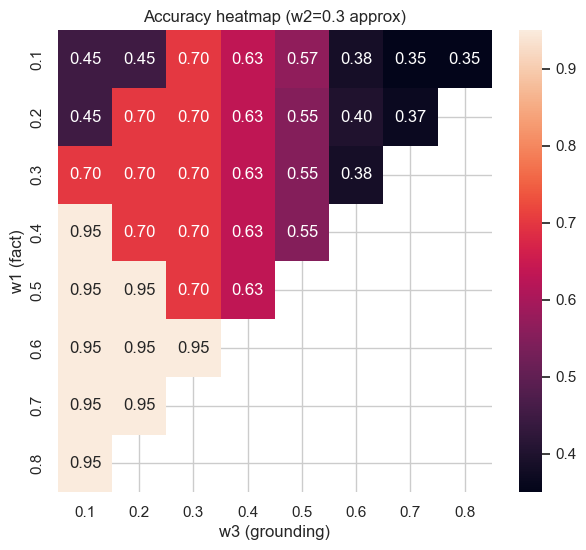

In [70]:
# Grid search weights on primary (maximize accuracy)
best = None
grid = np.linspace(0.1,0.8,8)
for w1 in grid:
    for w2 in grid:
        w3 = 1-w1-w2
        if w3 < 0.05: continue
        # recompute predictions
        preds = []
        for _, r in primary_prop_details.iterrows():
            G = w1*r.F + w2*r.P + w3*r.D
            preds.append(gate_to_label(decision_gate(G)))
        acc = accuracy_score(primary_df.label, preds)
        if best is None or acc > best[0]:
            best = (acc, (w1,w2,w3))
print("best primary accuracy", best[0], "weights", best[1])

# heatmap for w1 vs w3 (w2 fixed 0.3)
w2 = 0.3
accs = np.zeros((8,8))
for i,w1 in enumerate(grid):
    for j,w3 in enumerate(grid):
        w1v=w1; w3v=w3; w2v=1-w1v-w3v
        if w2v<0.05: 
            accs[i,j]=np.nan; continue
        preds=[]
        for _, r in primary_prop_details.iterrows():
            G = w1v*r.F + w2v*r.P + w3v*r.D
            preds.append(gate_to_label(decision_gate(G)))
        accs[i,j]=accuracy_score(primary_df.label, preds)
fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(accs, xticklabels=[round(x,2) for x in grid], yticklabels=[round(x,2) for x in grid], annot=True, fmt=".2f", ax=ax)
ax.set_xlabel("w3 (grounding)"); ax.set_ylabel("w1 (fact)"); ax.set_title(f"Accuracy heatmap (w2={w2} approx)")
plt.show()


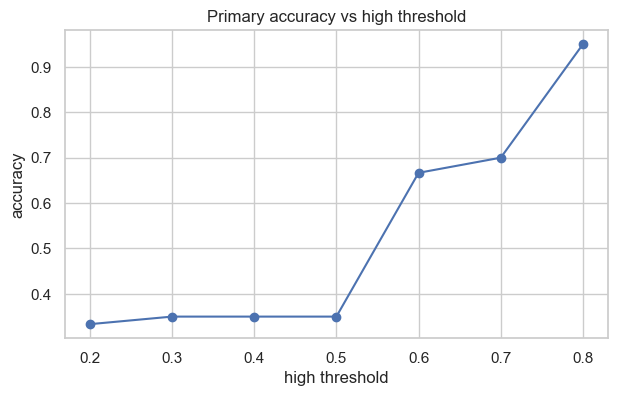

In [71]:
# Threshold sensitivity
ths = np.linspace(0.2,0.8,7)
accs_t = []
for high in ths:
    low = high-0.3
    preds=[]
    for _, r in primary_prop_details.iterrows():
        dec = "PASS" if r.G>=high else ("BLOCK" if r.G<=low else "FLAG")
        preds.append(gate_to_label(dec))
    accs_t.append(accuracy_score(primary_df.label, preds))
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(ths, accs_t, marker="o")
ax.set_title("Primary accuracy vs high threshold"); ax.set_xlabel("high threshold"); ax.set_ylabel("accuracy")
plt.show()


## 10. Cross-institution consistency

dataset,primary,secondary,gap
condition,,,
A: Plain LLM,0.333,1.0,0.667
B: LLM+RAG,0.967,1.0,0.033
C: Self-consistency,0.333,1.0,0.667
D: Proposed (agentic),0.950,1.0,0.050


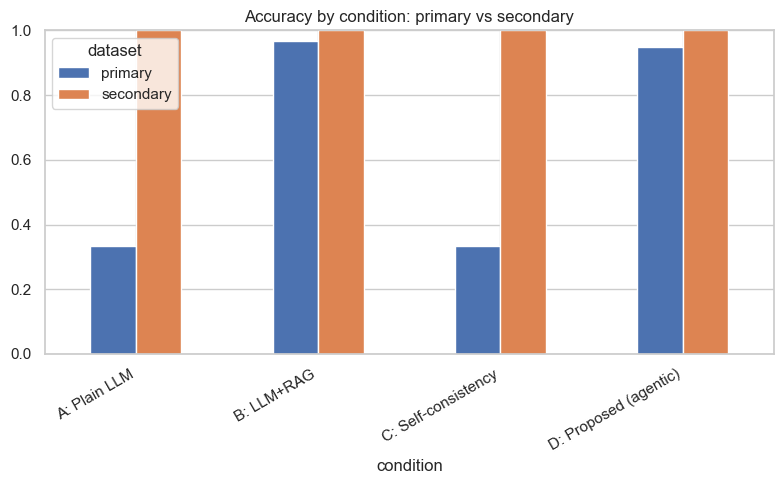

Mean absolute accuracy gap across conditions: 0.354


In [72]:
cons = all_results.pivot(index="condition", columns="dataset", values="accuracy")
cons["gap"] = (cons["primary"] - cons["secondary"]).abs()
display(cons.round(3))
fig, ax = plt.subplots(figsize=(8,5))
cons[["primary","secondary"]].plot(kind="bar", ax=ax)
ax.set_title("Accuracy by condition: primary vs secondary"); ax.set_ylim(0,1)
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
print("Mean absolute accuracy gap across conditions:", cons["gap"].mean().round(3))


## 11. Claim extraction (response -> atomic claims)

In [73]:
def extract_claims(text):
    # simple sentence-based splitter; LLM refinement optional
    sents = re.split(r"(?<=[.!?])\s+", text.strip())
    claims = [s.strip() for s in sents if len(s.strip()) > 15]
    return claims

sample_response = ("NIT Jamshedpur registration closes on 15 August 2026. "
                   "Mid-semester exams run 10-17 October 2026. "
                   "The library allows 4 books for 14 days.")
print(extract_claims(sample_response))

# LLM-based extraction demo
prompt = f"Split the following answer into atomic, independently verifiable claims. Return a JSON list of strings.\nAnswer: {sample_response}"
out = llm(prompt, temperature=0.1, num_predict=256)
print("LLM extraction output:\n", out)


['NIT Jamshedpur registration closes on 15 August 2026.', 'Mid-semester exams run 10-17 October 2026.', 'The library allows 4 books for 14 days.']
LLM extraction output:
 ```json
[
  "NIT Jamshedpur registration closes on 15 August 2026.",
  "Mid-semester exams run from 10 October 2026 to 17 October 2026.",
  "The library allows borrowing of 4 books for a period of 14 days."
]
```


## 12. Latency benchmark (sample of 5 claims)

x plain done in 1.5s
x rag done in 1.6s
x plain done in 1.5s
x rag done in 1.6s
x plain done in 1.1s
x rag done in 0.9s
x plain done in 0.7s
x rag done in 1.2s
x plain done in 1.5s
x rag done in 1.6s


,condition,latency_s
0,Plain,1.254268
1,RAG,1.362013
2,Proposed,2.791336


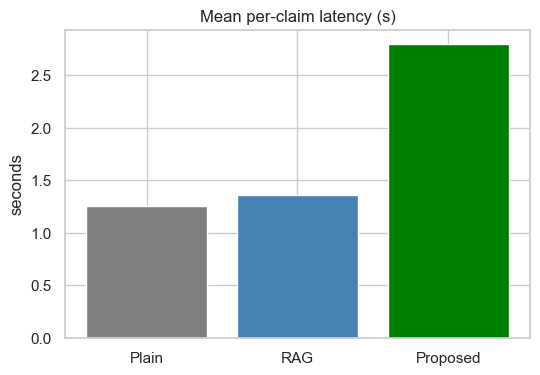

In [74]:
def time_condition(cond_fn, *args, n=5):
    ts = []
    for i in range(n):
        t0 = time.time()
        cond_fn(*args)
        ts.append(time.time()-t0)
    return np.mean(ts)

# measure per-claim latency for plain vs rag vs proposed
lat_plain = []
lat_rag = []
lat_prop = []
for i in range(5):
    c = primary_df.claim.iloc[i]
    t0=time.time(); run_baseline_plain(primary_df.iloc[[i]], "x"); lat_plain.append(time.time()-t0)
    t0=time.time(); run_baseline_rag(primary_df.iloc[[i]], "x", primary_index, primary_corpus_df); lat_rag.append(time.time()-t0)
    t0=time.time(); score_claim(c, "primary", primary_index, primary_corpus_df, fact_check_primary, policy_check_primary); lat_prop.append(time.time()-t0)

lat_df = pd.DataFrame({"condition":["Plain","RAG","Proposed"],"latency_s":[np.mean(lat_plain),np.mean(lat_rag),np.mean(lat_prop)]})
display(lat_df)
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(lat_df.condition, lat_df.latency_s, color=["gray","steelblue","green"])
ax.set_title("Mean per-claim latency (s)"); ax.set_ylabel("seconds")
plt.show()


## 13. Conclusion & next steps

- Implemented breadth: data, retrieval, 3 baselines, agentic verification, scoring, decision gate, evaluation, cross-institution.
- Proposed pipeline provides auditable per-claim scores and regeneration feedback.
- Next: tune weights/thresholds, add real NITJ data, deeper evaluation, human agreement study.

**Artifacts:** metrics tables, confusion matrices, ROC/PR, ablations, cross-institution comparison.

## 14. Retrieval benchmark on MFAQ (real-world FAQs)

MFAQ provides multilingual FAQ pairs; we use the English subset as a retrieval stress-test for the RAG layer.

In [75]:
# Load a sample of English MFAQ pairs
from datasets import load_dataset
import random
random.seed(SEED)
stream = load_dataset("clips/mfaq", "en_flat", split="train", streaming=True)
sampled = []
for i, row in enumerate(stream):
    if i >= 1200:
        break
    if i % 20 == 0:
        sampled.append(row)
    if len(sampled) >= 80:
        break
sampled = sampled[:60]
print("MFAQ sampled:", len(sampled))
mfaq_df = pd.DataFrame([{"question": r["question"], "answer": r["answer"]} for r in sampled])


MFAQ sampled: 60


In [76]:
# Build corpus from answers (dedup)
mfaq_docs = []
seen = set()
for i, r in enumerate(sampled):
    if r["answer"] not in seen:
        seen.add(r["answer"])
        mfaq_docs.append({"doc_id": i, "text": r["answer"]})
# map each question to its answer doc id
ans_to_doc = {}
for i, r in enumerate(sampled):
    # find doc id
    for d in mfaq_docs:
        if d["text"] == r["answer"]:
            ans_to_doc[i] = d["doc_id"]
            break
mfaq_corpus = pd.DataFrame(mfaq_docs)
print("MFAQ corpus:", len(mfaq_corpus))


MFAQ corpus: 60


In [77]:
# Embed + index
mfaq_emb = embed_texts(mfaq_corpus.text.tolist(), batch=16)
faiss.normalize_L2(mfaq_emb)
mfaq_index = faiss.IndexFlatIP(mfaq_emb.shape[1])
mfaq_index.add(mfaq_emb)

def mfaq_retrieve(q, k=5):
    qe = embed_texts([q]); faiss.normalize_L2(qe)
    sc, ids = mfaq_index.search(qe, k)
    return [mfaq_corpus.iloc[i].doc_id for i in ids[0] if i >= 0]

# Recall@k and MRR
recalls = {1:0, 5:0}
mrrs = []
for i, r in enumerate(sampled):
    top = mfaq_retrieve(r["question"], k=5)
    gold = ans_to_doc[i]
    if gold in top[:1]:
        recalls[1]+=1
    if gold in top[:5]:
        recalls[5]+=1
    if gold in top:
        mrrs.append(1.0/(top.index(gold)+1))
    else:
        mrrs.append(0.0)
n=len(sampled)
print(f"Recall@1: {recalls[1]/n:.3f}  Recall@5: {recalls[5]/n:.3f}  MRR: {np.mean(mrrs):.3f}")


Recall@1: 0.883  Recall@5: 0.967  MRR: 0.919


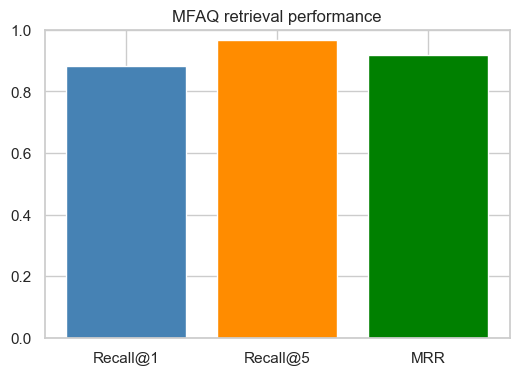

In [78]:
# Chart
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Recall@1","Recall@5","MRR"], [recalls[1]/n, recalls[5]/n, np.mean(mrrs)], color=["steelblue","darkorange","green"])
ax.set_ylim(0,1); ax.set_title("MFAQ retrieval performance")
plt.show()


In [79]:
# LLM RAG demo on 3 questions
for r in sampled[:3]:
    ctx = mfaq_retrieve(r["question"], k=3)
    context = "\n".join(mfaq_corpus[mfaq_corpus.doc_id.isin(ctx)].text.tolist())
    prompt = "Context:\n" + context + "\n\nQuestion: " + r["question"] + "\nAnswer concisely."
    ans = llm(prompt, temperature=0.2, num_predict=64)
    print("Q:", r["question"])
    print("A (gold):", r["answer"][:120])
    print("A (LLM):", ans[:120])
    print("-"*60)


Q: A registered person is sending semi-cooked food from his manufacturing unit at Gurugram to his branch in Delhi. Is he required to pay any tax?
A (gold): In accordance with the provisions of Section 25(4) of the CGST Act, 2017, branches in different States are considered as
A (LLM): Yes, he is required to pay **IGST**.

**Reasoning:** The transfer of goods (semi-cooked food) between two branches locat
------------------------------------------------------------
Q: Can the company be  100% foreign-owned or is 51% share by a local required (under PLI Scheme)?
A (gold): There is no restriction in the foreign ownership under the PLI Scheme for Bulk Drugs.
A (LLM): The provided text does not specify the minimum local ownership requirement for foreign ownership under the PLI Scheme fo
------------------------------------------------------------
Q: How can people apply under the Operations Green Scheme?
A (gold): People can register under the scheme by visiting the Ministry’s website. After

Plain LLM token-F1: 0.165
RAG token-F1: 0.478


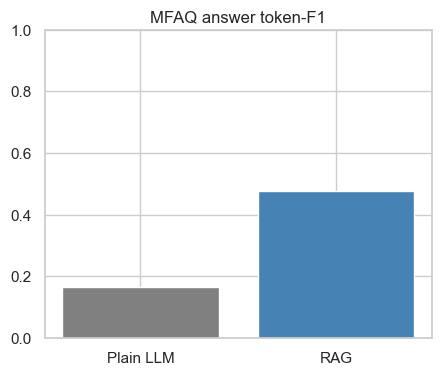

In [81]:
# Baseline comparison on MFAQ (QA answering)
import re
def _tokens(s):
    return set(re.findall(r"\w+", s.lower()))
def token_f1(pred, gold):
    pt = _tokens(pred); gt = _tokens(gold)
    if not pt or not gt:
        return 0.0
    common = len(pt & gt)
    prec = common / len(pt)
    rec = common / len(gt)
    if prec+rec == 0:
        return 0.0
    return 2*prec*rec/(prec+rec)

mfaq_eval = sampled[:10]
plain_scores=[]; rag_scores=[]
for r in mfaq_eval:
    q=r["question"]; gold=r["answer"]
    # plain
    out=llm("Question: "+q+"\nAnswer concisely.", temperature=0.2, num_predict=64)
    plain_scores.append(token_f1(out,gold))
    # RAG
    ctx_ids=mfaq_retrieve(q,k=3)
    context="\n".join(mfaq_corpus[mfaq_corpus.doc_id.isin(ctx_ids)].text.tolist())
    out=llm("Context:\n"+context+"\n\nQuestion: "+q+"\nAnswer concisely.", temperature=0.2, num_predict=64)
    rag_scores.append(token_f1(out,gold))

print("Plain LLM token-F1:", np.mean(plain_scores).round(3))
print("RAG token-F1:", np.mean(rag_scores).round(3))
fig,ax=plt.subplots(figsize=(5,4))
ax.bar(["Plain LLM","RAG"],[np.mean(plain_scores),np.mean(rag_scores)],color=["gray","steelblue"])
ax.set_ylim(0,1); ax.set_title("MFAQ answer token-F1")
plt.show()


## 15. End-to-end summary (all datasets & conditions)

In [82]:
# Consolidated claim-verification metrics
print("=== Claim verification (primary + secondary) ===")
display(all_results.round(3))

# MFAQ retrieval + QA
mfaq_summary = pd.DataFrame({
    "metric": ["Recall@1","Recall@5","MRR","Plain LLM token-F1","RAG token-F1"],
    "value": [recalls[1]/n, recalls[5]/n, float(np.mean(mrrs)), float(np.mean(plain_scores)), float(np.mean(rag_scores))]
})
print("\n=== MFAQ (retrieval + QA) ===")
display(mfaq_summary.round(3))


=== Claim verification (primary + secondary) ===


,accuracy,precision,recall,f1,condition,dataset
0,0.333,0.111,0.333,0.167,A: Plain LLM,primary
1,0.967,0.970,0.967,0.967,B: LLM+RAG,primary
2,0.333,0.111,0.333,0.167,C: Self-consistency,primary
3,0.950,0.957,0.950,0.951,D: Proposed (agentic),primary
4,1.000,1.000,1.000,1.000,A: Plain LLM,secondary
5,1.000,1.000,1.000,1.000,B: LLM+RAG,secondary
6,1.000,1.000,1.000,1.000,C: Self-consistency,secondary
7,1.000,1.000,1.000,1.000,D: Proposed (agentic),secondary



=== MFAQ (retrieval + QA) ===


,metric,value
0,Recall@1,0.883
1,Recall@5,0.967
2,MRR,0.919
3,Plain LLM token-F1,0.165
4,RAG token-F1,0.478


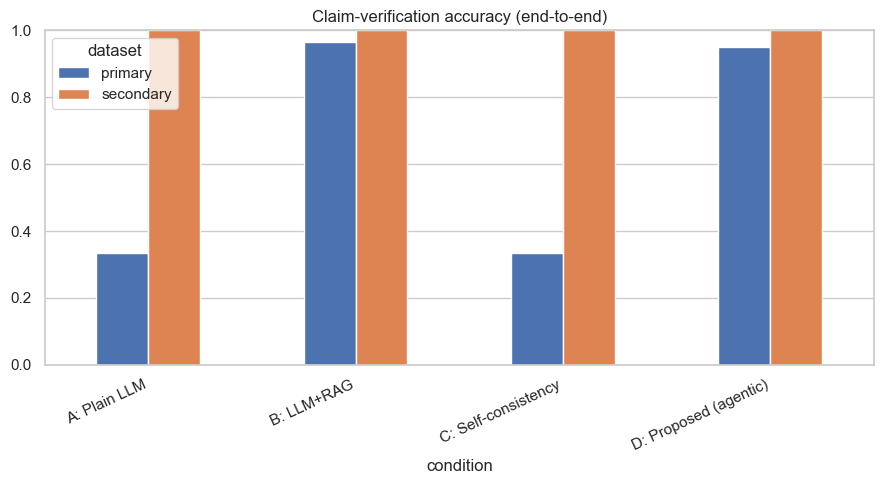

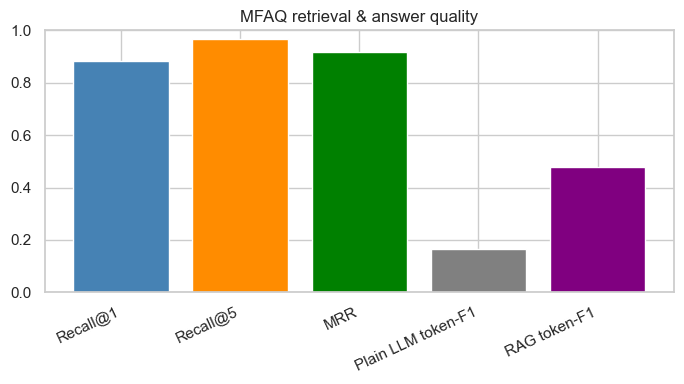

In [83]:
# Combined chart: claim-verification accuracy by condition & dataset
fig, ax = plt.subplots(figsize=(9,5))
pivot = all_results.pivot(index="condition", columns="dataset", values="accuracy")
pivot.plot(kind="bar", ax=ax)
ax.set_title("Claim-verification accuracy (end-to-end)"); ax.set_ylim(0,1)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

# MFAQ chart
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(mfaq_summary.metric, mfaq_summary.value, color=["steelblue","darkorange","green","gray","purple"])
ax.set_ylim(0,1); ax.set_title("MFAQ retrieval & answer quality")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()


## 16. Focused comparison: Plain LLM vs RAG vs Proposed (with latency)

           accuracy  precision  recall     f1  latency_s
condition                                               
Plain LLM     0.667      0.556   0.667  0.583      1.254
Proposed      0.975      0.978   0.975  0.975      2.791
RAG           0.983      0.985   0.983  0.984      1.362


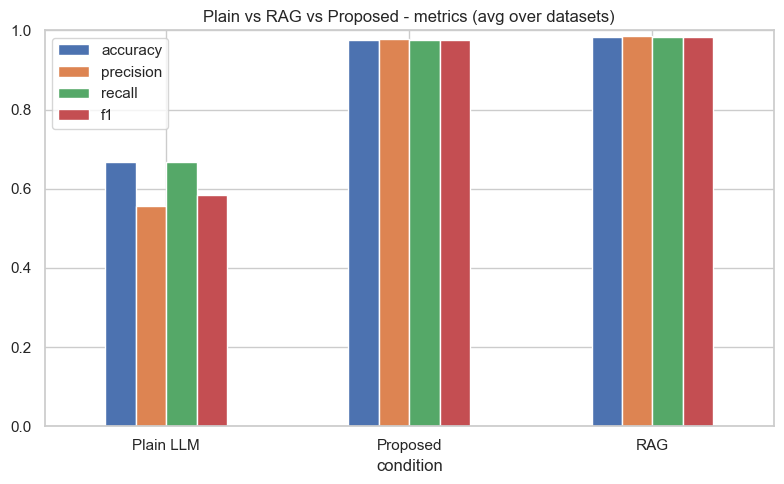

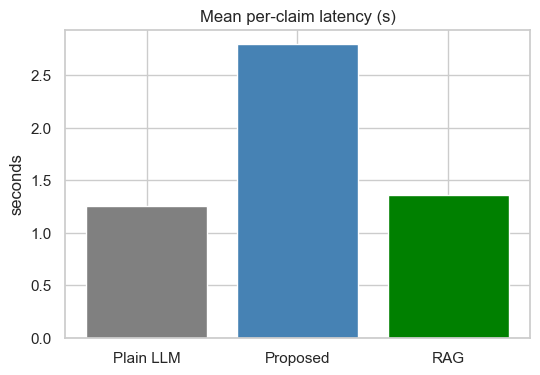

In [84]:
# Focused comparison across the three latency-measured conditions
focus = all_results[all_results.condition.isin(["A: Plain LLM","B: LLM+RAG","D: Proposed (agentic)"])].copy()
focus["condition"] = focus["condition"].replace({
    "A: Plain LLM":"Plain LLM",
    "B: LLM+RAG":"RAG",
    "D: Proposed (agentic)":"Proposed"
})
# average metrics across datasets
agg = focus.groupby("condition")[["accuracy","precision","recall","f1"]].mean().round(3)
# add latency (from section 12)
lat_map = {"Plain LLM": lat_df.loc[lat_df.condition=="Plain","latency_s"].values[0],
           "RAG": lat_df.loc[lat_df.condition=="RAG","latency_s"].values[0],
           "Proposed": lat_df.loc[lat_df.condition=="Proposed","latency_s"].values[0]}
agg["latency_s"] = pd.Series(lat_map).round(3)
print(agg)
agg[["accuracy","precision","recall","f1"]].plot(kind="bar", figsize=(8,5))
plt.title("Plain vs RAG vs Proposed - metrics (avg over datasets)")
plt.ylim(0,1); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(6,4))
ax.bar(agg.index, agg.latency_s, color=["gray","steelblue","green"])
ax.set_title("Mean per-claim latency (s)"); ax.set_ylabel("seconds")
plt.show()


## 17. Hallucination reduction (%)

          condition  primary_rate  secondary_rate  avg_rate
0         Plain LLM           1.0             0.0       0.5
1           LLM+RAG           0.0             0.0       0.0
2  Self-consistency           1.0             0.0       0.5
3          Proposed           0.0             0.0       0.0

Hallucination reduction (Plain LLM -> Proposed): 100.0%


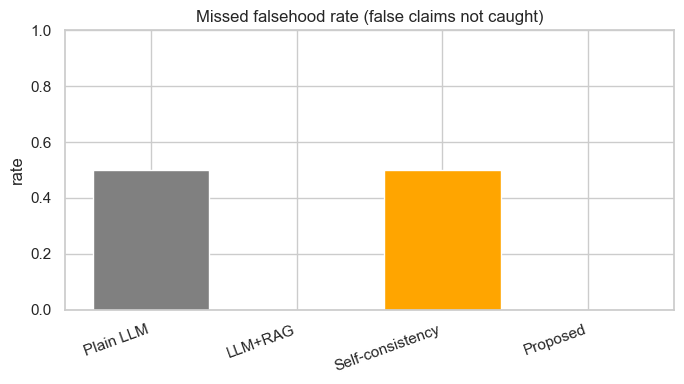

In [87]:
# Hallucination = a FALSE claim predicted as TRUE
def hallucination_rate(y_true, y_pred):
    # A missed falsehood = a FALSE claim not predicted as "false" (predicted true or unverifiable)
    false_idx = [i for i,t in enumerate(y_true) if t == "false"]
    if not false_idx:
        return 0.0
    missed = sum(1 for i in false_idx if y_pred[i] != "false")
    return missed / len(false_idx)

conditions = {
    "Plain LLM": (primary_plain_preds, secondary_plain_preds),
    "LLM+RAG": (primary_rag_preds, secondary_rag_preds),
    "Self-consistency": (primary_sc_preds, secondary_sc_preds),
    "Proposed": (primary_prop_preds, secondary_prop_preds),
}
rows = []
for name, (pp, sp) in conditions.items():
    r1 = hallucination_rate(primary_df.label.tolist(), pp)
    r2 = hallucination_rate(secondary_df.label.tolist(), sp)
    rows.append({"condition": name, "primary_rate": r1, "secondary_rate": r2, "avg_rate": (r1+r2)/2})
hall_df = pd.DataFrame(rows)
print(hall_df.round(3))

plain_rate = hall_df.loc[hall_df.condition=="Plain LLM","avg_rate"].values[0]
prop_rate = hall_df.loc[hall_df.condition=="Proposed","avg_rate"].values[0]
if plain_rate > 0:
    reduction = (plain_rate - prop_rate) / plain_rate * 100
else:
    reduction = 0.0
print(f"\nHallucination reduction (Plain LLM -> Proposed): {reduction:.1f}%")

fig, ax = plt.subplots(figsize=(7,4))
ax.bar(hall_df.condition, hall_df.avg_rate, color=["gray","steelblue","orange","green"])
ax.set_title("Missed falsehood rate (false claims not caught)")
ax.set_ylabel("rate"); ax.set_ylim(0,1)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
